## Generating a dataset

Purpose: We want to assess the correlation of structure (e.g. lipophilicity) of some molecules with their inhibitory activity for Acetylcholinesterase (AChE). First of all:

Import dependencies and load the two datasets for activities (ChEMBL) and molecular descriptors (PubChem).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load both datasets
act = pd.read_csv("data/ache_activities.csv")
desc = pd.read_csv("data/ache_pubchem_descriptors.csv")

# Keep only relevant columns from ChEMBL
act = act[["canonical_smiles", "pchembl_value", "standard_relation", "standard_type"]]

# Aggregate (some SMILES might appear multiple times → average or median)
act = act.groupby("canonical_smiles", as_index=False)["pchembl_value"].median()



Inspect the two datasets.

Combine the two datasets.

In [ ]:
# Merge on canonical_smiles, how="inner" drops all rows which are only contained in one df
merged = pd.merge(act, desc, on="canonical_smiles", how="inner") #merge needs left and right, "how" defines how to treat missing values / what do we do with access. Inner only takes those that directly correspond to dataset
# Inner only keeps those that are common. Fills blancks 

print(f"Merged dataset: {len(merged)} entries")
merged.head()

Now, inspect the combined dataframe. Look for abnomalies, i.e. duplicates and missing data.

Decide what to do with the bad data points and proceed. Make sure to document properly and preserve the original dataframe.

Run a quick EDA on the cleaned dataset including some plots. What can you conclude?

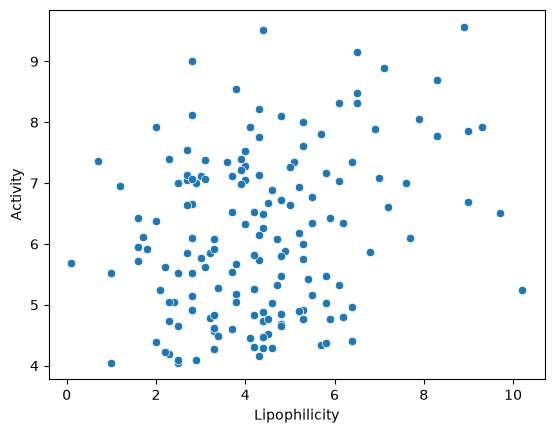

In [ ]:
sns.scatterplot(x=df_clean["XLogP"], y=df_clean["pchembl_value"])
plt.xlabel("Lipophilicity")
plt.ylabel("Activity")
plt.show()

Export the cleaned dataset as "ache_qsar_data.csv".

In [ ]:
df_clean.to_csv("data/ache_qsar_data.csv", index=False)

In [ ]:
df_clean.to_csv("data/ache_qsar_data.csv", index=False)